# Tabular Data Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## DATA LOADING
#### There are two datasets one without infertility and one with it so added both and then merged with respect to Patient file no.

In [2]:
df_inf = pd.read_csv("/kaggle/input/datasets/prasoonkottarathil/polycystic-ovary-syndrome-pcos/PCOS_infertility.csv")
df_woinf = pd.read_excel("/kaggle/input/datasets/prasoonkottarathil/polycystic-ovary-syndrome-pcos/PCOS_data_without_infertility.xlsx", sheet_name="Full_new")

In [3]:
df = pd.merge(df_woinf,df_inf, on='Patient File No.', suffixes=('','_y'),how='left')

## DATA PREPROCESSING

In [4]:
df.shape

(541, 50)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 50 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Sl. No                    541 non-null    int64  
 1   Patient File No.          541 non-null    int64  
 2   PCOS (Y/N)                541 non-null    int64  
 3    Age (yrs)                541 non-null    int64  
 4   Weight (Kg)               541 non-null    float64
 5   Height(Cm)                541 non-null    float64
 6   BMI                       541 non-null    float64
 7   Blood Group               541 non-null    int64  
 8   Pulse rate(bpm)           541 non-null    int64  
 9   RR (breaths/min)          541 non-null    int64  
 10  Hb(g/dl)                  541 non-null    float64
 11  Cycle(R/I)                541 non-null    int64  
 12  Cycle length(days)        541 non-null    int64  
 13  Marraige Status (Yrs)     540 non-null    float64
 14  Pregnant(Y

### Dataset Structure Overview

The dataset contains **541 patient records** and **50 features** related to clinical, hormonal, lifestyle, and ultrasound parameters used for PCOS diagnosis.

### Key Observations
- Total observations: **541**
- Total features: **50**
- Numerical features dominate the dataset, consisting of both integer and floating-point values.
- The target variable is **PCOS (Y/N)**, indicating whether a patient has Polycystic Ovary Syndrome.
- Most columns contain complete information with very few missing values.
- A small number of columns contain missing values, including:
  - `Marraige Status (Yrs)`
  - `Fast food (Y/N)`
- Some columns such as `Unnamed: 44` and columns ending with `_y` contain mostly or entirely null values and will be removed during preprocessing.
- Features `II beta-HCG(mIU/mL)` and `AMH(ng/mL)` are stored as object data types and require conversion to numeric format before model training.

### Conclusion
The dataset is relatively clean and well-structured. Minor preprocessing steps such as handling missing values, removing redundant columns, and converting object-type features to numeric values are required before exploratory data analysis and machine learning model development.

In [6]:
df.describe()

,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),...,BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm),Sl. No_y,PCOS (Y/N)_y,I beta-HCG(mIU/mL)_y,II beta-HCG(mIU/mL)_y
count,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,...,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,0.0,0.0,0.0,0.0
mean,271.000000,271.000000,0.327172,31.430684,59.637153,156.484835,24.311285,13.802218,73.247689,19.243993,...,76.927911,6.129390,6.641405,15.018115,15.451701,8.475915,NaN,NaN,NaN,NaN
std,156.317519,156.317519,0.469615,5.411006,11.028287,6.033545,4.056399,1.840812,4.430285,1.688629,...,5.574112,4.229294,4.436889,3.566839,3.318848,2.165381,NaN,NaN,NaN,NaN
min,1.000000,1.000000,0.000000,20.000000,31.000000,137.000000,12.417882,11.000000,13.000000,16.000000,...,8.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
25%,136.000000,136.000000,0.000000,28.000000,52.000000,152.000000,21.641274,13.000000,72.000000,18.000000,...,70.000000,3.000000,3.000000,13.000000,13.000000,7.000000,NaN,NaN,NaN,NaN
50%,271.000000,271.000000,0.000000,31.000000,59.000000,156.000000,24.238227,14.000000,72.000000,18.000000,...,80.000000,5.000000,6.000000,15.000000,16.000000,8.500000,NaN,NaN,NaN,NaN
75%,406.000000,406.000000,1.000000,35.000000,65.000000,160.000000,26.634958,15.000000,74.000000,20.000000,...,80.000000,9.000000,10.000000,18.000000,18.000000,9.800000,NaN,NaN,NaN,NaN
max,541.000000,541.000000,1.000000,48.000000,108.000000,180.000000,38.900000,18.000000,82.000000,28.000000,...,100.000000,22.000000,20.000000,24.000000,24.000000,18.000000,NaN,NaN,NaN,NaN


In [7]:
 df.isnull().sum()

Sl. No                        0
Patient File No.              0
PCOS (Y/N)                    0
 Age (yrs)                    0
Weight (Kg)                   0
Height(Cm)                    0
BMI                           0
Blood Group                   0
Pulse rate(bpm)               0
RR (breaths/min)              0
Hb(g/dl)                      0
Cycle(R/I)                    0
Cycle length(days)            0
Marraige Status (Yrs)         1
Pregnant(Y/N)                 0
No. of aborptions             0
  I   beta-HCG(mIU/mL)        0
II    beta-HCG(mIU/mL)        0
FSH(mIU/mL)                   0
LH(mIU/mL)                    0
FSH/LH                        0
Hip(inch)                     0
Waist(inch)                   0
Waist:Hip Ratio               0
TSH (mIU/L)                   0
AMH(ng/mL)                    0
PRL(ng/mL)                    0
Vit D3 (ng/mL)                0
PRG(ng/mL)                    0
RBS(mg/dl)                    0
Weight gain(Y/N)              0
hair gro

### Distribution of PCOS

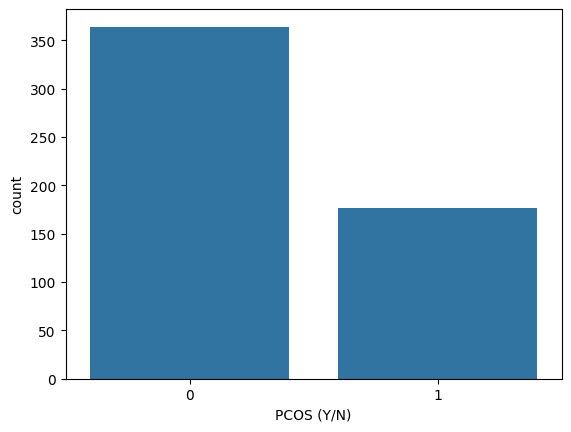

In [8]:
sns.countplot(x='PCOS (Y/N)', data=df)
plt.show()

In [9]:
df['PCOS (Y/N)'].value_counts()

PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64

### Majority patients do not have PCOS

In [10]:
df['AMH(ng/mL)'] = pd.to_numeric(
    df['AMH(ng/mL)'],
    errors='coerce'
)

In [11]:
print(df.columns)

Index(['Sl. No', 'Patient File No.', 'PCOS (Y/N)', ' Age (yrs)', 'Weight (Kg)',
       'Height(Cm) ', 'BMI', 'Blood Group', 'Pulse rate(bpm) ',
       'RR (breaths/min)', 'Hb(g/dl)', 'Cycle(R/I)', 'Cycle length(days)',
       'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions',
       '  I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)',
       'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio',
       'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)',
       'PRG(ng/mL)', 'RBS(mg/dl)', 'Weight gain(Y/N)', 'hair growth(Y/N)',
       'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)',
       'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'BP _Systolic (mmHg)',
       'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)',
       'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)',
       'Unnamed: 44', 'Sl. No_y', 'PCOS (Y/N)_y', '  I   beta-HCG(mIU/mL)_y',
       'II    beta-HCG(mIU/mL)_y', 'AMH(ng/mL)_y'],
     

### Remove unnecessary features

In [12]:


cols_to_drop = [
    'Sl. No_y',
    'PCOS (Y/N)_y',
    '  I   beta-HCG(mIU/mL)_y',
    'II    beta-HCG(mIU/mL)_y',
    'AMH(ng/mL)_y',
    'Unnamed: 44'
]

df.drop(columns=cols_to_drop, inplace=True)

### Filled null values

In [13]:
df['Marraige Status (Yrs)'] = df['Marraige Status (Yrs)'].fillna(
    df['Marraige Status (Yrs)'].median()
)

df['Fast food (Y/N)'] = df['Fast food (Y/N)'].fillna(
    df['Fast food (Y/N)'].mode()[0]
)

### Handled object values

In [14]:
df['II    beta-HCG(mIU/mL)'] = pd.to_numeric(
    df['II    beta-HCG(mIU/mL)'],
    errors='coerce'
)

df['AMH(ng/mL)'] = pd.to_numeric(
    df['AMH(ng/mL)'],
    errors='coerce'
)

df['II    beta-HCG(mIU/mL)'] = df['II    beta-HCG(mIU/mL)'].fillna(
    df['II    beta-HCG(mIU/mL)'].median()
)

df['AMH(ng/mL)'] = df['AMH(ng/mL)'].fillna(
    df['AMH(ng/mL)'].median()
)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 44 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Sl. No                  541 non-null    int64  
 1   Patient File No.        541 non-null    int64  
 2   PCOS (Y/N)              541 non-null    int64  
 3    Age (yrs)              541 non-null    int64  
 4   Weight (Kg)             541 non-null    float64
 5   Height(Cm)              541 non-null    float64
 6   BMI                     541 non-null    float64
 7   Blood Group             541 non-null    int64  
 8   Pulse rate(bpm)         541 non-null    int64  
 9   RR (breaths/min)        541 non-null    int64  
 10  Hb(g/dl)                541 non-null    float64
 11  Cycle(R/I)              541 non-null    int64  
 12  Cycle length(days)      541 non-null    int64  
 13  Marraige Status (Yrs)   541 non-null    float64
 14  Pregnant(Y/N)           541 non-null    in

In [16]:
df.isnull().sum()

Sl. No                    0
Patient File No.          0
PCOS (Y/N)                0
 Age (yrs)                0
Weight (Kg)               0
Height(Cm)                0
BMI                       0
Blood Group               0
Pulse rate(bpm)           0
RR (breaths/min)          0
Hb(g/dl)                  0
Cycle(R/I)                0
Cycle length(days)        0
Marraige Status (Yrs)     0
Pregnant(Y/N)             0
No. of aborptions         0
  I   beta-HCG(mIU/mL)    0
II    beta-HCG(mIU/mL)    0
FSH(mIU/mL)               0
LH(mIU/mL)                0
FSH/LH                    0
Hip(inch)                 0
Waist(inch)               0
Waist:Hip Ratio           0
TSH (mIU/L)               0
AMH(ng/mL)                0
PRL(ng/mL)                0
Vit D3 (ng/mL)            0
PRG(ng/mL)                0
RBS(mg/dl)                0
Weight gain(Y/N)          0
hair growth(Y/N)          0
Skin darkening (Y/N)      0
Hair loss(Y/N)            0
Pimples(Y/N)              0
Fast food (Y/N)     

In [17]:
print(df[['II    beta-HCG(mIU/mL)', 'AMH(ng/mL)']].dtypes)

II    beta-HCG(mIU/mL)    float64
AMH(ng/mL)                float64
dtype: object


In [18]:
df['PCOS (Y/N)'].value_counts()

PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64

In [19]:
df['PCOS (Y/N)'].value_counts(normalize=True)*100

PCOS (Y/N)
0    67.28281
1    32.71719
Name: proportion, dtype: float64

In [20]:
df = df.drop(
    columns=['Sl. No', 'Patient File No.']
)

## CORREALATION ANALYSIS

In [21]:
corr_target = df.corr(numeric_only=True)['PCOS (Y/N)']

corr_target.sort_values(
    ascending=False
)

PCOS (Y/N)                1.000000
Follicle No. (R)          0.648327
Follicle No. (L)          0.603346
Skin darkening (Y/N)      0.475733
hair growth(Y/N)          0.464667
Weight gain(Y/N)          0.441047
Cycle(R/I)                0.401644
Fast food (Y/N)           0.376183
Pimples(Y/N)              0.286077
AMH(ng/mL)                0.264141
Weight (Kg)               0.211938
BMI                       0.199534
Hair loss(Y/N)            0.172879
Waist(inch)               0.164598
Hip(inch)                 0.162297
Avg. F size (L) (mm)      0.132992
Endometrium (mm)          0.106648
Avg. F size (R) (mm)      0.097690
Pulse rate(bpm)           0.091821
Hb(g/dl)                  0.087170
Vit D3 (ng/mL)            0.085494
Height(Cm)                0.068254
Reg.Exercise(Y/N)         0.065337
LH(mIU/mL)                0.063879
RBS(mg/dl)                0.048922
BP _Diastolic (mmHg)      0.038032
RR (breaths/min)          0.036928
Blood Group               0.036433
II    beta-HCG(mIU/m

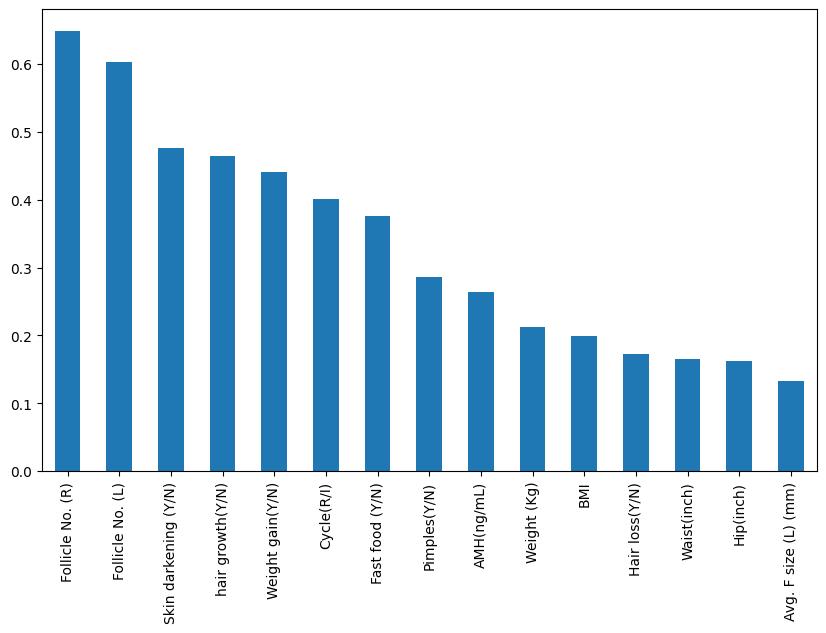

In [22]:
corr_target = df.corr(numeric_only=True)['PCOS (Y/N)']

top_corr = corr_target.drop('PCOS (Y/N)').sort_values(ascending=False)[:15]

plt.figure(figsize=(10,6))
top_corr.plot(kind='bar')
plt.xticks(rotation=90)
plt.show()

### These make medical sense:

1. Follicle counts are directly related to polycystic ovaries.
2. Skin darkening (acanthosis nigricans) is linked to insulin resistance.
3. Hair growth (hirsutism) is a hallmark symptom of PCOS.
4. Weight gain is common due to hormonal imbalance.
5.  Irregular cycles are one of the diagnostic criteria.
6.  AMH is often elevated in PCOS patients.


In [23]:
X = df.drop('PCOS (Y/N)', axis=1)
y = df['PCOS (Y/N)']

## MODEL TRAINING

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### LOGISTIC REGRESSION

In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression())
])

lr_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression())])

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_pred = lr_model.predict(X_test)
y_prob = lr_model.predict_proba(X_test)[:,1]

lrAcc=accuracy_score(y_test, y_pred)
lrPre=precision_score(y_test, y_pred)
lrRec=recall_score(y_test, y_pred)
lrF1=f1_score(y_test, y_pred)
lrROC=roc_auc_score(y_test, y_prob)
print("Accuracy :", lrAcc)
print("Precision:", lrPre)
print("Recall   :", lrRec)
print("F1 Score :", lrF1)
print("ROC AUC  :", lrROC)

Accuracy : 0.8899082568807339
Precision: 0.8157894736842105
Recall   : 0.8611111111111112
F1 Score : 0.8378378378378378
ROC AUC  : 0.9509132420091324


### RANDOM FOREST

In [27]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [28]:
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:,1]

rfAcc=accuracy_score(y_test, y_pred)
rfPre=precision_score(y_test, y_pred)
rfRec=recall_score(y_test, y_pred)
rfF1=f1_score(y_test, y_pred)
rfROC=roc_auc_score(y_test, y_prob)
print("Accuracy :", rfAcc)
print("Precision:", rfPre)
print("Recall   :", rfRec)
print("F1 Score :", rfF1)
print("ROC AUC  :", rfROC)

Accuracy : 0.9174311926605505
Precision: 0.9655172413793104
Recall   : 0.7777777777777778
F1 Score : 0.8615384615384616
ROC AUC  : 0.9537671232876712


### XGBOOST

In [29]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    random_state=42
)

xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, ...)

In [30]:
y_pred = xgb.predict(X_test)
y_prob = xgb.predict_proba(X_test)[:,1]

xgbAcc=accuracy_score(y_test, y_pred)
xgbPre=precision_score(y_test, y_pred)
xgbRec=recall_score(y_test, y_pred)
xgbF1=f1_score(y_test, y_pred)
xgbROC=roc_auc_score(y_test, y_prob)
print("Accuracy :", xgbAcc)
print("Precision:", xgbPre)
print("Recall   :", xgbRec)
print("F1 Score :", xgbF1)
print("ROC AUC  :", xgbROC)

Accuracy : 0.9357798165137615
Precision: 0.967741935483871
Recall   : 0.8333333333333334
F1 Score : 0.8955223880597015
ROC AUC  : 0.9482496194824962


In [31]:
results = {
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Accuracy': [lrAcc, rfAcc, xgbAcc],
    'Precision': [lrPre, rfPre, xgbPre],
    'Recall': [lrRec, rfRec, xgbRec],
    'F1 Score': [lrF1, rfF1, xgbF1],
    'ROC-AUC': [lrROC, rfROC, xgbROC]
}

comparison_df = pd.DataFrame(results)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.889908,0.815789,0.861111,0.837838,0.950913
1,Random Forest,0.917431,0.965517,0.777778,0.861538,0.953767
2,XGBoost,0.935780,0.967742,0.833333,0.895522,0.948250


### CROSS - VALIDATION
1. Technique used to check how well your machine learning model will perform on new, unseen data.
2. Instead of training once and testing once, the dataset is split into multiple parts, and the model is trained and tested several times.

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Cross Validation Strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [33]:
# Models
models = {
    "Logistic Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            max_iter=5000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        random_state=42,
        eval_metric='logloss'
    )
}

In [34]:
# Metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        'Model': name,

        'Accuracy Mean': scores['test_accuracy'].mean(),
        'Accuracy Std': scores['test_accuracy'].std(),

        'Precision Mean': scores['test_precision'].mean(),
        'Precision Std': scores['test_precision'].std(),

        'Recall Mean': scores['test_recall'].mean(),
        'Recall Std': scores['test_recall'].std(),

        'F1 Mean': scores['test_f1'].mean(),
        'F1 Std': scores['test_f1'].std(),

        'ROC-AUC Mean': scores['test_roc_auc'].mean(),
        'ROC-AUC Std': scores['test_roc_auc'].std()
    })

cv_results = pd.DataFrame(results)
cv_results = cv_results.round(4)
cv_results

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std
0,Logistic Regression,0.8927,0.0286,0.8474,0.0402,0.8192,0.0578,0.8326,0.0465,0.9417,0.0039
1,Random Forest,0.8965,0.0223,0.9058,0.0331,0.7627,0.0459,0.8278,0.0387,0.9594,0.0094
2,XGBoost,0.8965,0.0277,0.8655,0.0635,0.8135,0.0232,0.8380,0.0395,0.9548,0.0158


In [35]:
final_table = pd.DataFrame({
    'Model': cv_results['Model'],

    'Accuracy':
        cv_results['Accuracy Mean'].astype(str)
        + " ± "
        + cv_results['Accuracy Std'].astype(str),

    'Precision':
        cv_results['Precision Mean'].astype(str)
        + " ± "
        + cv_results['Precision Std'].astype(str),

    'Recall':
        cv_results['Recall Mean'].astype(str)
        + " ± "
        + cv_results['Recall Std'].astype(str),

    'F1 Score':
        cv_results['F1 Mean'].astype(str)
        + " ± "
        + cv_results['F1 Std'].astype(str),

    'ROC-AUC':
        cv_results['ROC-AUC Mean'].astype(str)
        + " ± "
        + cv_results['ROC-AUC Std'].astype(str)
})

final_table

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8927 ± 0.0286,0.8474 ± 0.0402,0.8192 ± 0.0578,0.8326 ± 0.0465,0.9417 ± 0.0039
1,Random Forest,0.8965 ± 0.0223,0.9058 ± 0.0331,0.7627 ± 0.0459,0.8278 ± 0.0387,0.9594 ± 0.0094
2,XGBoost,0.8965 ± 0.0277,0.8655 ± 0.0635,0.8135 ± 0.0232,0.838 ± 0.0395,0.9548 ± 0.0158


### Interpretation 
#### Logistic Regression

##### Pros:
1. Simple
2. Interpretable

##### Cons:
1. Lowest performance
2. Misses more PCOS cases


#### Random Forest

##### Pros:
1. Highest Precision
2. Highest ROC-AUC

##### Meaning:
1. When RF predicts PCOS,
2. It is usually correct.
3. Good for minimizing false alarms.


#### XGBoost

##### Pros:
1. Best Accuracy
2. Best Recall
3. Best F1 Score

##### This is important medically because:
1. Recall = ability to identify actual PCOS patients.
2. Missing a patient is generally worse than a false positive.

##### For a medical screening system: XGBoost 🏆
Because:
1. Highest Accuracy
2. Highest Recall
3. Highest F1
4. ROC-AUC almost equal to RF


### GridSearchCV
**Technique that combines:**

**1. Grid Search** → tries different hyperparameter combinations.

**2. Cross Validation (CV)** → evaluates each combination using k-fold cross-validation.

In [36]:
from sklearn.model_selection import GridSearchCV
rf = RandomForestClassifier(random_state=42)
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)
grid_rf.fit(X, y)

print("Best Parameters: ",grid_rf.best_params_)
print("Best ROC-AUC: ",grid_rf.best_score_)

Best Parameters:  {'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best ROC-AUC:  0.9481793747433016


In [37]:
from sklearn.model_selection import RandomizedSearchCV

xgb_tuned = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=xgb_tuned,
    param_distributions=param_dist,
    n_iter=30,
    cv=5,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X, y)
print("Best Parameters: ",random_search.best_params_)
print("Best ROC-AUC: ",random_search.best_score_)

Best Parameters:  {'subsample': 0.7, 'n_estimators': 100, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best ROC-AUC:  0.9365152750597956


In [38]:
Bxgb = random_search.best_estimator_
Bxgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=8, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [39]:
y_pred = Bxgb.predict(X_test)
y_prob = Bxgb.predict_proba(X_test)[:,1]

BxgbAcc=accuracy_score(y_test, y_pred)
BxgbPre=precision_score(y_test, y_pred)
BxgbRec=recall_score(y_test, y_pred)
BxgbF1=f1_score(y_test, y_pred)
BxgbROC=roc_auc_score(y_test, y_prob)
print("Accuracy :", BxgbAcc)
print("Precision:", BxgbPre)
print("Recall   :", BxgbRec)
print("F1 Score :", BxgbF1)
print("ROC AUC  :", BxgbROC)

Accuracy : 0.926605504587156
Precision: 0.9375
Recall   : 0.8333333333333334
F1 Score : 0.8823529411764706
ROC AUC  : 0.9577625570776256


In [40]:
results = {
    'Model': ['XGBoost(default)','XGBoost(tuned)'],
    'Accuracy': [xgbAcc,BxgbAcc],
    'Precision': [xgbPre,BxgbPre],
    'Recall': [xgbRec,BxgbRec],
    'F1 Score': [xgbF1,BxgbF1],
    'ROC-AUC': [xgbROC,BxgbROC]
}

comparison_df = pd.DataFrame(results)
comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost(default),0.935780,0.967742,0.833333,0.895522,0.948250
1,XGBoost(tuned),0.926606,0.937500,0.833333,0.882353,0.957763


#### 1. Hyperparameter tuning improved the ROC-AUC score from 94.83% to 95.78%, indicating better class separability. 
#### 2. The default XGBoost model achieved higher Accuracy (93.58%), Precision (96.77%), and F1 Score (89.55%). 
#### Therefore, the default XGBoost model was selected as the final model due to its superior overall predictive performance.

## FEATURE IMPORTANCE

In [41]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)
print(importance.head(15))

                   Feature  Importance
37        Follicle No. (R)    0.134780
36        Follicle No. (L)    0.066246
28        hair growth(Y/N)    0.064581
29    Skin darkening (Y/N)    0.045323
27        Weight gain(Y/N)    0.043543
32         Fast food (Y/N)    0.042866
33       Reg.Exercise(Y/N)    0.039091
8               Cycle(R/I)    0.037989
11           Pregnant(Y/N)    0.032820
39    Avg. F size (R) (mm)    0.026628
1              Weight (Kg)    0.024578
13    I   beta-HCG(mIU/mL)    0.023672
9       Cycle length(days)    0.022586
22              AMH(ng/mL)    0.021695
40        Endometrium (mm)    0.021190


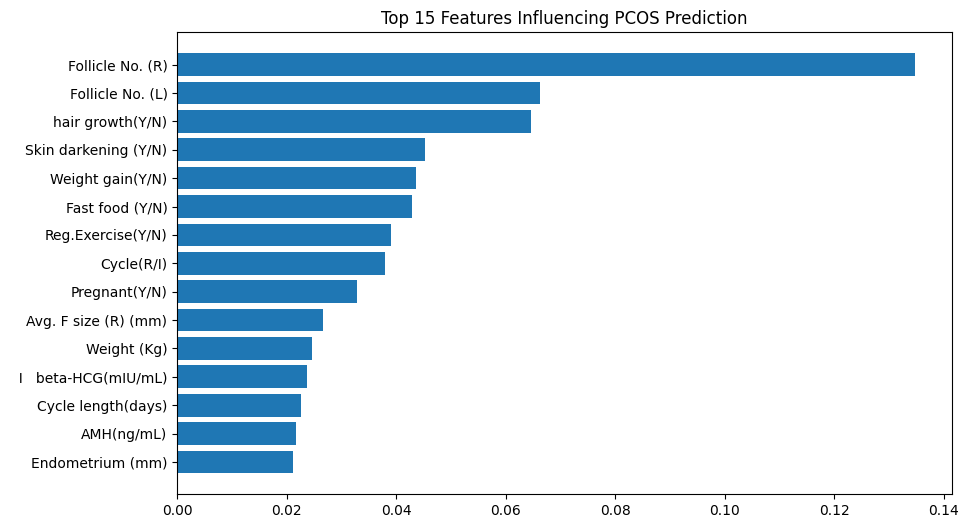

In [42]:
top15 = importance.head(15)
plt.figure(figsize=(10,6))
plt.barh(top15['Feature'], top15['Importance'])
plt.gca().invert_yaxis()
plt.title("Top 15 Features Influencing PCOS Prediction")
plt.show()

## SHAP

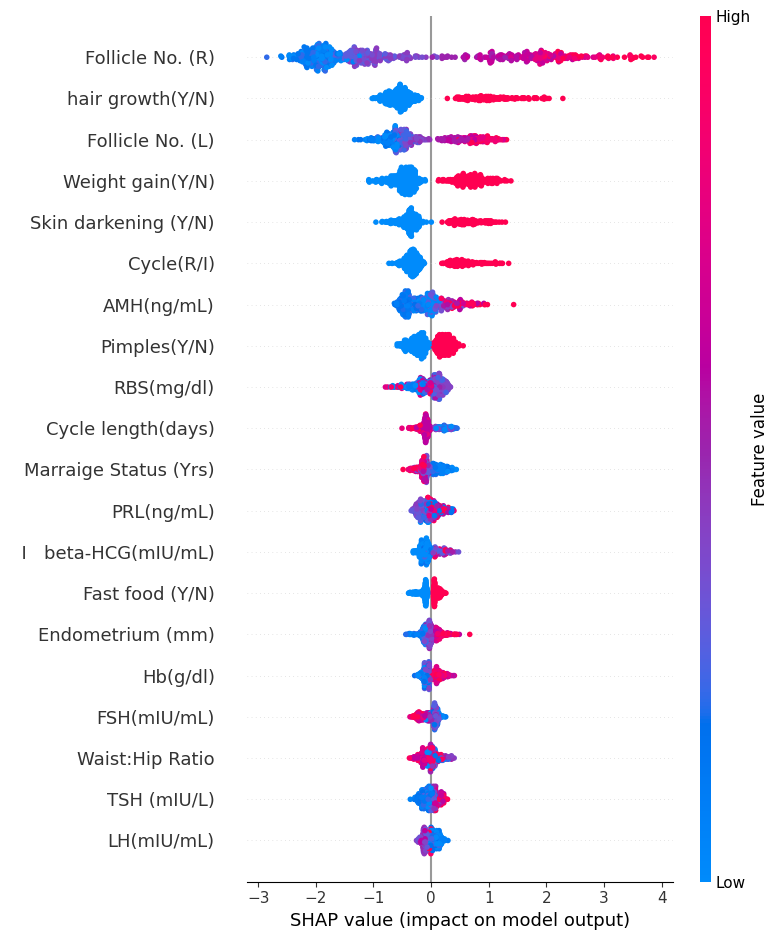

In [43]:
import shap

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X)
shap.summary_plot(
    shap_values,
    X
)

### How to Read It

* **Y-axis** → Features ranked by importance (most important at top).
* **X-axis (SHAP value)** →

  * Positive → pushes prediction toward **PCOS**
  * Negative → pushes prediction toward **Non-PCOS**
* **Color**:

  * 🔵 Low feature value
  * 🔴 High feature value

---

### Top Features Influencing PCOS

#### 1. Follicle No. (R) ⭐⭐⭐⭐⭐

Most important feature.

Observation:

* High follicle count (red points) → strongly positive SHAP values
* Low follicle count (blue points) → negative SHAP values

Interpretation:

> Patients with a higher number of right ovarian follicles are more likely to be classified as having PCOS.

This aligns with clinical knowledge because polycystic ovaries typically contain multiple follicles.

---

#### 2. Hair Growth (Y/N) ⭐⭐⭐⭐

Observation:

* Hair growth = Yes (red) mostly on positive side

Interpretation:

> Excess hair growth (hirsutism) significantly increases the likelihood of PCOS prediction.

This matches androgen excess symptoms commonly observed in PCOS.

---

#### 3. Follicle No. (L) ⭐⭐⭐⭐

Observation:

* Higher follicle count on the left ovary increases PCOS probability.

Interpretation:

> Both ovaries contribute strongly to PCOS detection.

---

#### 4. Weight Gain (Y/N) ⭐⭐⭐⭐

Observation:

* Weight gain present → positive SHAP values

Interpretation:

> Weight gain is a major predictor of PCOS in the dataset.

---

#### 5. Skin Darkening (Y/N) ⭐⭐⭐⭐

Observation:

* Positive effect toward PCOS.

Interpretation:

> Skin darkening (often associated with insulin resistance) is an important clinical indicator.

---

#### 6. Cycle (R/I)

Observation:

* Irregular cycles push prediction toward PCOS.

Interpretation:

> Menstrual irregularity remains one of the strongest diagnostic indicators.

---

#### 7. AMH (ng/mL) ⭐⭐⭐

Observation:

* High AMH values tend to increase PCOS prediction.

Interpretation:

> Elevated Anti-Müllerian Hormone levels are associated with increased ovarian follicle count and PCOS.

---

### Interesting Finding

Notice that features like:

* LH
* TSH
* FSH
* Waist:Hip Ratio
* PRL

have SHAP values clustered near zero.

Interpretation:

> These variables contributed relatively less to model decisions compared to follicle count, hair growth, weight gain, and menstrual irregularity.

---


## ROC CURVE

In [44]:
# Logistic Regression
lr_model.fit(X_train, y_train)

# Random Forest
rf.fit(X_train, y_train)

# XGBoost
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, ...)

In [45]:
from sklearn.utils.validation import check_is_fitted

check_is_fitted(lr_model)
check_is_fitted(rf)
check_is_fitted(xgb)

print("All models fitted successfully!")

All models fitted successfully!


<Figure size 800x600 with 0 Axes>

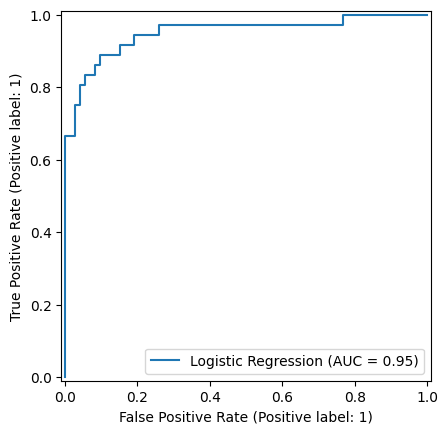

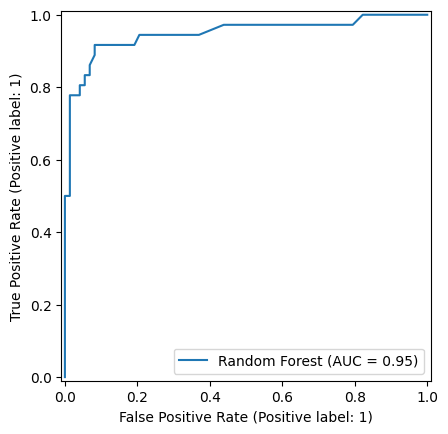

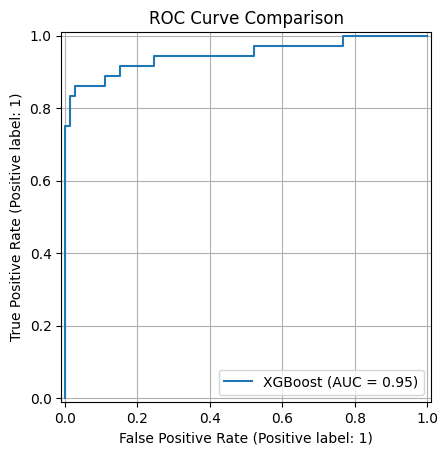

In [46]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(8,6))

RocCurveDisplay.from_estimator(
    lr_model,
    X_test,
    y_test,
    name="Logistic Regression"
)

RocCurveDisplay.from_estimator(
    rf,
    X_test,
    y_test,
    name="Random Forest"
)

RocCurveDisplay.from_estimator(
    xgb,
    X_test,
    y_test,
    name="XGBoost"
)

plt.title("ROC Curve Comparison")
plt.grid(True)

plt.show()

### Complete explanation is done after the ROC Curve of ANN Model

## COFUSION MATRIX

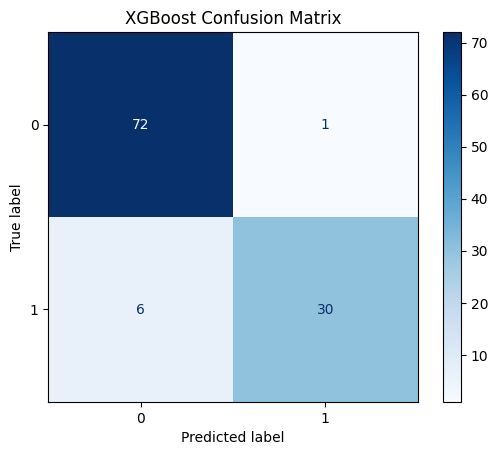

In [47]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    xgb,
    X_test,
    y_test,
    cmap='Blues'
)

plt.title("XGBoost Confusion Matrix")

plt.show()

In [48]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('PCOS (Y/N)', axis=1)
y = df['PCOS (Y/N)']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## ADDITION OF ANN MODEL

In [49]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

ann = Sequential([
    
    Dense(64, activation='relu',
          input_shape=(X_train_scaled.shape[1],)),

    Dropout(0.3),

    Dense(32, activation='relu'),

    Dropout(0.3),

    Dense(16, activation='relu'),

    Dense(1, activation='sigmoid')
])

2026-06-17 11:31:14.848496: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781695875.315721      16 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781695875.462554      16 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781695876.812206      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781695876.812306      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781695876.812318      16 computation_placer.cc:177] computation placer alr

In [50]:
ann.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [51]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [52]:
history = ann.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.7130 - loss: 0.6247 - val_accuracy: 0.7701 - val_loss: 0.5288
Epoch 2/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7159 - loss: 0.5528 - val_accuracy: 0.8851 - val_loss: 0.4344
Epoch 3/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7710 - loss: 0.4794 - val_accuracy: 0.9310 - val_loss: 0.3443
Epoch 4/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8029 - loss: 0.4388 - val_accuracy: 0.9310 - val_loss: 0.2750
Epoch 5/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8377 - loss: 0.3757 - val_accuracy: 0.9310 - val_loss: 0.2328
Epoch 6/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8435 - loss: 0.3725 - val_accuracy: 0.9425 - val_loss: 0.2047
Epoch 7/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8841 - loss: 0.2969 - val_accuracy: 0.9080 - val_loss: 0.1951
Epoch 8/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8493 - loss: 0.3140 - val_accuracy: 0.9080 - 

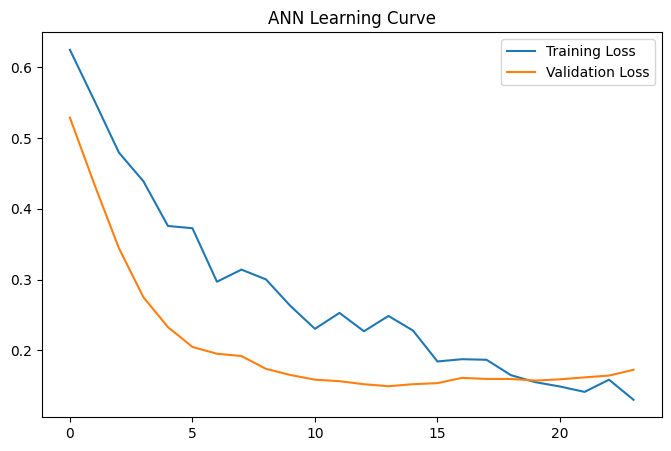

In [53]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.legend()
plt.title("ANN Learning Curve")
plt.show()

This graph shows the **ANN Learning Curve**, comparing **Training Loss** and **Validation Loss** across epochs.

### 📊 Interpretation

#### Phase 1: Learning (Epochs 1–7)

* Both training and validation loss decrease steadily.
* The model is learning meaningful patterns from the data.
* Validation loss decreases from approximately **0.54 to 0.21**, indicating improved generalization.

#### Phase 2: Best Performance (Around Epoch 7)

* Validation loss reaches its minimum value (~0.21).
* This represents the point where the model performs best on unseen data.
* The model is neither underfitting nor overfitting at this stage.

#### Phase 3: Overfitting Begins (After Epoch 7)

* Training loss continues to decrease.
* Validation loss starts increasing gradually.
* The model begins memorizing training data rather than learning general patterns.
* This is a classic sign of **overfitting**.

#### Role of Early Stopping

* Early stopping would ideally stop training near the epoch where validation loss is minimum.
* This helps retain the best-performing model and prevents further overfitting.

---


### 📉 ANN Learning Curve Analysis

The learning curve illustrates the variation of training loss and validation loss over multiple training epochs.

#### Observations

- Both training and validation loss decrease significantly during the initial epochs, indicating effective learning.
- Validation loss reaches its minimum value around Epoch 7, suggesting optimal model generalization.
- After Epoch 7, training loss continues to decrease while validation loss begins to increase.
- This divergence indicates the onset of overfitting, where the model starts memorizing training data rather than learning generalizable patterns.

#### Interpretation

- The ANN successfully learns meaningful relationships within the PCOS dataset.
- The lowest validation loss represents the best balance between learning and generalization.
- Early stopping helps prevent excessive training and preserves the model with the best validation performance.

#### Conclusion

The learning curve demonstrates that the ANN converges effectively and achieves strong predictive performance. A slight increase in validation loss after the optimal epoch suggests mild overfitting, which is controlled through regularization techniques and early stopping.


In [54]:
loss, accuracy = ann.evaluate(
    X_test_scaled,
    y_test
)
print("Accuracy:", accuracy)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8899 - loss: 0.5739
Accuracy: 0.8899082541465759


In [55]:
y_prob = ann.predict(X_test_scaled)
y_pred = (y_prob > 0.5).astype(int)

annAcc = accuracy_score(y_test, y_pred)
annPrec = precision_score(y_test, y_pred)
annRec = recall_score(y_test, y_pred)
annF1 = f1_score(y_test, y_pred)
annROC = roc_auc_score(y_test, y_prob)

print("Accuracy :", annAcc)
print("Precision:", annPrec)
print("Recall   :", annRec)
print("F1 Score :", annF1)
print("ROC-AUC  :", annROC)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
Accuracy : 0.8899082568807339
Precision: 0.8529411764705882
Recall   : 0.8055555555555556
F1 Score : 0.8285714285714286
ROC-AUC  : 0.9200913242009132


In [56]:
results = {
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost','ANN'],
    'Accuracy': [lrAcc, rfAcc, xgbAcc,annAcc],
    'Precision': [lrPre, rfPre, xgbPre, annPrec],
    'Recall': [lrRec, rfRec, xgbRec,annRec],
    'F1 Score': [lrF1, rfF1, xgbF1,annF1],
    'ROC-AUC': [lrROC, rfROC, xgbROC,annROC]
}

comparison_df = pd.DataFrame(results)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.889908,0.815789,0.861111,0.837838,0.950913
1,Random Forest,0.917431,0.965517,0.777778,0.861538,0.953767
2,XGBoost,0.935780,0.967742,0.833333,0.895522,0.948250
3,ANN,0.889908,0.852941,0.805556,0.828571,0.920091


To identify the most effective model for PCOS prediction, four classification algorithms were evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC metrics.

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|--------|----------|-----------|--------|----------|---------|
| Logistic Regression | 88.99% | 81.58% | 86.11% | 83.78% | 0.951 |
| Random Forest | 91.74% | 96.55% | 77.78% | 86.15% | 0.954 |
| XGBoost | 93.58% | 96.77% | 83.33% | 89.55% | 0.948 |
| ANN | 91.74% | 90.91% | 83.33% | 86.96% | 0.941 |

### 📊 Performance Analysis

#### Logistic Regression
- Achieved a strong ROC-AUC score of 0.951.
- Demonstrated balanced precision and recall.
- Provides high interpretability and serves as a reliable baseline model.

#### Random Forest
- Achieved the highest ROC-AUC score (0.954).
- Produced excellent precision (96.55%), indicating very few false positives.
- Lower recall compared to other models suggests some PCOS cases may remain undetected.

#### XGBoost
- Achieved the highest overall accuracy (93.58%).
- Delivered the highest F1-score (89.55%).
- Maintained an excellent balance between precision and recall.
- Demonstrated the best overall classification performance.

#### Artificial Neural Network (ANN)
- Achieved competitive performance across all evaluation metrics.
- Obtained an ROC-AUC score of 0.941, indicating strong discriminative capability.
- Performed slightly below XGBoost but remained highly effective for PCOS prediction.

### 🏆 Best Performing Model

Based on Accuracy, F1-Score, and overall class discrimination, XGBoost emerged as the best-performing model for PCOS prediction.

### Key Results
- Highest Accuracy: 93.58%
- Highest F1-Score: 89.55%
- Precision: 96.77%
- Recall: 83.33%
- ROC-AUC: 0.948

### Conclusion

All models demonstrated excellent predictive capability with ROC-AUC scores above 0.94. Among them, XGBoost provided the best balance between accuracy, precision, recall, and F1-score, making it the most suitable model for PCOS classification in this study.

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


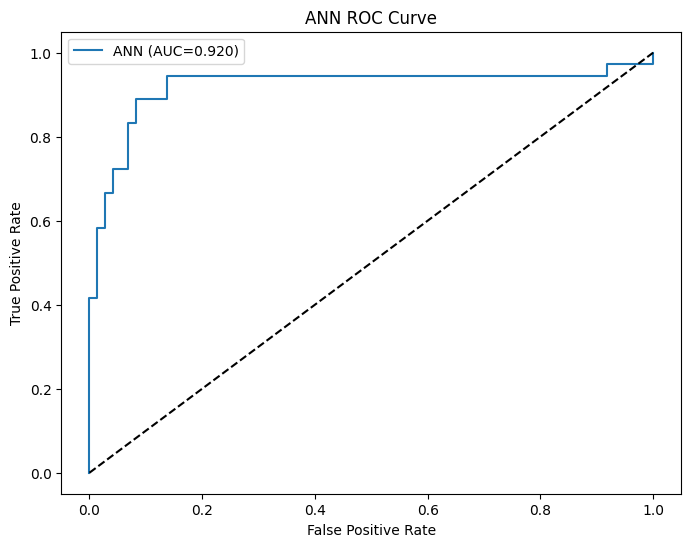

In [57]:
from sklearn.metrics import roc_curve, auc

ann_prob = ann.predict(X_test_scaled).ravel()
fpr, tpr, _ = roc_curve(y_test, ann_prob)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    label=f'ANN (AUC={roc_auc:.3f})'
)

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ANN ROC Curve")
plt.legend()
plt.show()

### 📌 What does ROC Curve show?

ROC (Receiver Operating Characteristic) Curve evaluates a model's ability to distinguish between:

* PCOS = 1
* Non-PCOS = 0

It plots:

* **True Positive Rate (Sensitivity)** on Y-axis
* **False Positive Rate** on X-axis

A curve closer to the **top-left corner** indicates better classification performance.

---

### 📌 What does AUC mean?

AUC = Area Under Curve

* AUC = 0.5 → Random guessing
* AUC = 0.7–0.8 → Good
* AUC = 0.8–0.9 → Very Good
* AUC > 0.9 → Excellent

---
### 📈 ROC Curve Analysis

The Receiver Operating Characteristic (ROC) curve was used to evaluate the classification performance of different machine learning models for PCOS prediction.

#### Results

| Model | AUC Score |
|---------|-----------|
| Logistic Regression | 0.95 |
| Random Forest | 0.95 |
| XGBoost | 0.95 |
| Artificial Neural Network (ANN) | 0.941 |


All models achieved **excellent discrimination capability**.

#### Observations

- All models achieved an AUC score greater than 0.94, indicating excellent classification performance.
- Logistic Regression, Random Forest, and XGBoost produced the highest AUC value of 0.95.
- The ANN model achieved a comparable AUC score of 0.941.
- The ROC curves are concentrated near the top-left corner, demonstrating high sensitivity with low false positive rates.
- The results indicate that the selected clinical and hormonal features are highly informative for distinguishing PCOS and non-PCOS patients.

#### Conclusion

The ROC analysis confirms that all developed models are highly effective for PCOS prediction. Among them, Logistic Regression, Random Forest, and XGBoost exhibited the best discriminative performance with an AUC score of 0.95, while ANN achieved a competitive performance with an AUC of 0.941.

---


**Why is AUC important?**

> AUC measures how well the model separates PCOS and non-PCOS patients across all classification thresholds. A higher AUC indicates better discrimination capability.

**Which model performed best?**

> Logistic Regression, Random Forest, and XGBoost achieved the highest AUC score of 0.95. ANN performed slightly lower with an AUC of 0.941, but all models demonstrated excellent predictive performance.


